In [85]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [86]:
train_df = pd.read_csv('train.csv')
test_df  = pd.read_csv('test.csv')

print(train_df)
print(test_df)

             medical_specialty  \
0     cardiovascular-pulmonary   
1     cardiovascular-pulmonary   
2     cardiovascular-pulmonary   
3     cardiovascular-pulmonary   
4     cardiovascular-pulmonary   
...                        ...   
2608                   surgery   
2609                   surgery   
2610                   surgery   
2611                   surgery   
2612                   surgery   

                                            description  \
0     chest pain possible syncopal spells she has be...   
1     the patient is 14 months old comes in with a c...   
2     fiberoptic bronchoscopy diagnostic hemoptysis ...   
3        left lower extremity venous doppler ultrasound   
4     the patient was admitted after undergoing a dr...   
...                                                 ...   
2608  thoracic right sided discectomy at t8 t9 the p...   
2609  acute acalculous cholecystitis open cholecyste...   
2610  arthrodesis anterior interbody technique anter...   
2

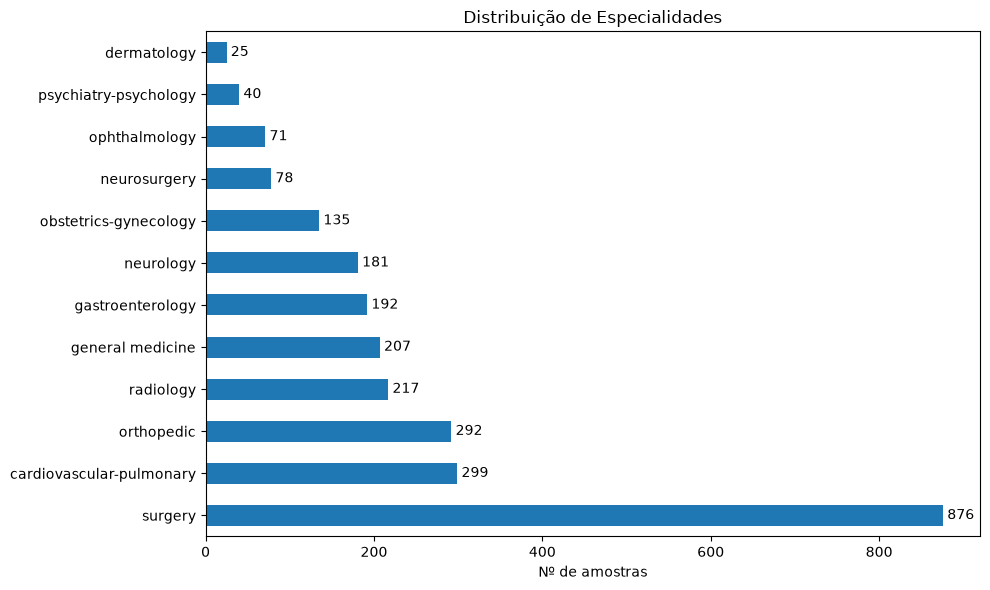

In [87]:
def summarize(df: pd.DataFrame):
    counts = df['medical_specialty'].value_counts()

    ax = counts.plot(kind='barh', figsize=(10, 6))
    ax.bar_label(ax.containers[0], padding=3)
    ax.set_xlabel("Nº de amostras")
    ax.set_ylabel("")
    plt.title("Distribuição de Especialidades")
    plt.tight_layout()
    plt.show()

summarize(train_df)


In [88]:
print(train_df['keywords'].isna().sum())
print(test_df['keywords'].isna().sum())

0
0


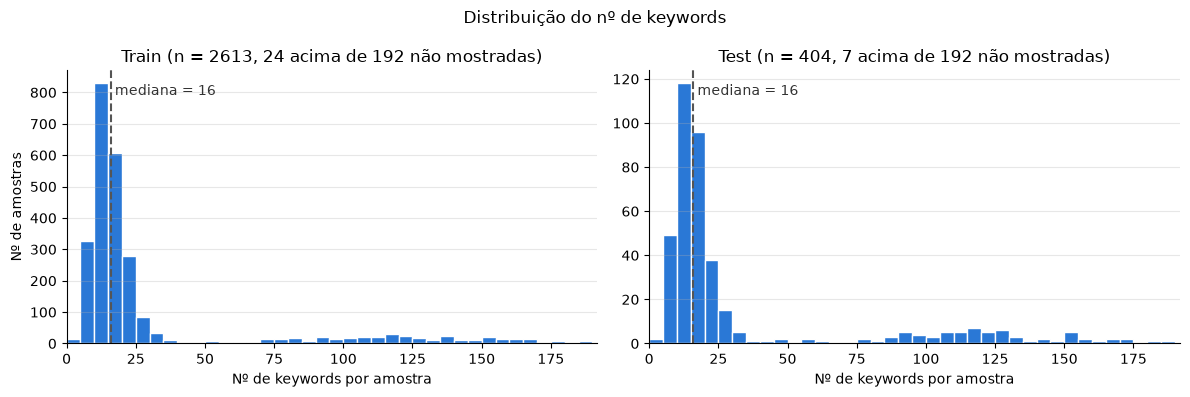

In [89]:
def plot_keywords_dist(dfs: dict[str, pd.DataFrame]):
    counts = {name: df['keywords'].str.split(',').str.len() for name, df in dfs.items()}

    upper = np.percentile(pd.concat(counts.values()), 99)    # corta outliers extremos
    bins  = np.arange(0, upper + 5, 5)

    fig, axes = plt.subplots(1, len(dfs), figsize=(12, 4))

    for ax, (name, n_keywords) in zip(np.atleast_1d(axes), counts.items()):
        n_out = (n_keywords > upper).sum()

        ax.hist(n_keywords, bins=bins, color='#2a78d6', edgecolor='white', linewidth=1)
        ax.axvline(n_keywords.median(), color='#555555', linestyle='--', linewidth=1.5)
        ax.text(n_keywords.median(), ax.get_ylim()[1] * 0.95, f' mediana = {n_keywords.median():.0f}', color='#333333', va='top')

        ax.set_xlim(0, upper)
        ax.set_title(f"{name} (n = {len(n_keywords)}, {n_out} acima de {upper:.0f} não mostradas)")
        ax.set_xlabel("Nº de keywords por amostra")
        ax.grid(axis='y', alpha=0.3)
        ax.spines[['top', 'right']].set_visible(False)

    np.atleast_1d(axes)[0].set_ylabel("Nº de amostras")
    fig.suptitle("Distribuição do nº de keywords")
    plt.tight_layout()
    plt.show()

plot_keywords_dist({'Train': train_df, 'Test': test_df})


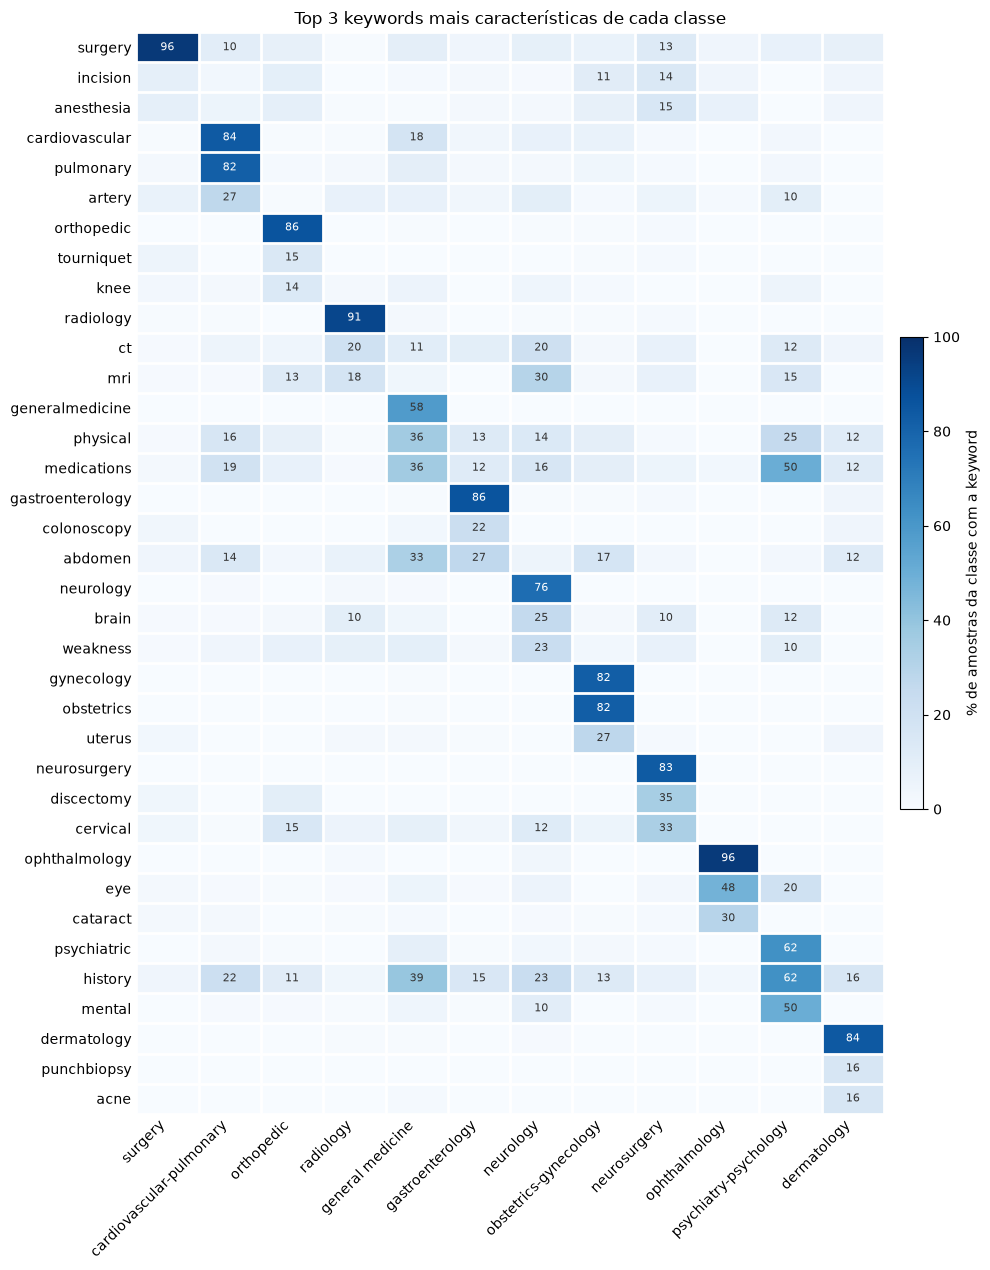

In [90]:
def plot_keywords_per_class(df: pd.DataFrame, top_n: int = 3):
    kw = df.assign(keyword=df['keywords'].str.split(',')).explode('keyword')
    kw = kw[kw['keyword'] != ''].reset_index()[['index', 'medical_specialty', 'keyword']].drop_duplicates()

    class_size = df['medical_specialty'].value_counts()

    # nº de amostras de cada classe que contêm a keyword
    in_cls = pd.crosstab(kw['keyword'], kw['medical_specialty'])[class_size.index]
    total  = in_cls.sum(axis=1)

    # % na classe vs % no resto das classes
    share   = in_cls.div(class_size, axis=1) * 100
    outside = in_cls.rsub(total, axis=0).div(len(df) - class_size, axis=1) * 100
    lift    = share - outside

    # top_n keywords mais características de cada classe (sem repetir)
    selected = []
    for cls in class_size.index:
        selected += [k for k in lift[cls].sort_values(ascending=False).index if k not in selected][:top_n]

    data = share.loc[selected]

    fig, ax = plt.subplots(figsize=(10, len(selected) * 0.3 + 2))
    im = ax.imshow(data, cmap='Blues', vmin=0, vmax=100, aspect='auto')

    ax.set_xticks(range(len(data.columns)), data.columns, rotation=45, ha='right')
    ax.set_yticks(range(len(data.index)), data.index)
    ax.set_xticks(np.arange(-.5, len(data.columns)), minor=True)
    ax.set_yticks(np.arange(-.5, len(data.index)), minor=True)
    ax.grid(which='minor', color='white', linewidth=2)
    ax.tick_params(which='both', length=0)
    ax.spines[:].set_visible(False)

    for i in range(len(data.index)):
        for j in range(len(data.columns)):
            v = data.iat[i, j]
            if v >= 10:
                ax.text(j, i, f'{v:.0f}', ha='center', va='center', fontsize=8, color='white' if v > 60 else '#333333')

    fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02, label="% de amostras da classe com a keyword")
    ax.set_title(f"Top {top_n} keywords mais características de cada classe")
    plt.tight_layout()
    plt.show()

plot_keywords_per_class(train_df)


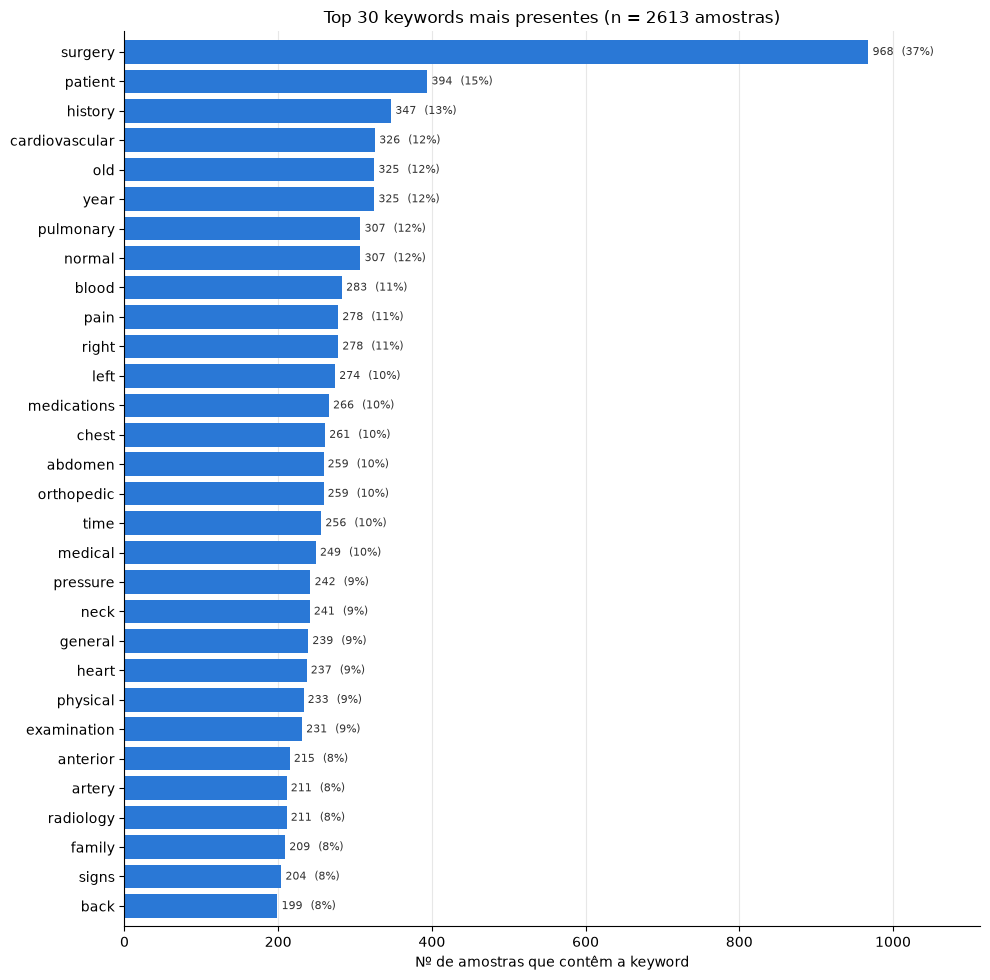

In [91]:
def plot_top_keywords(df: pd.DataFrame, top_n: int = 30):
    kw = df['keywords'].str.split(',').apply(lambda l: set(k for k in l if k))    # cada keyword conta 1x por amostra

    counts = kw.explode().value_counts().head(top_n)[::-1]

    fig, ax = plt.subplots(figsize=(10, top_n * 0.28 + 1.5))
    bars = ax.barh(counts.index, counts.values, color='#2a78d6', height=0.8)
    ax.bar_label(bars, labels=[f'{v}  ({v / len(df):.0%})' for v in counts.values], padding=3, fontsize=8, color='#333333')

    ax.set_xlabel("Nº de amostras que contêm a keyword")
    ax.set_xlim(0, counts.max() * 1.15)
    ax.margins(y=0.01)
    ax.grid(axis='x', alpha=0.3)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
    ax.set_title(f"Top {top_n} keywords mais presentes (n = {len(df)} amostras)")
    plt.tight_layout()
    plt.show()

plot_top_keywords(train_df)


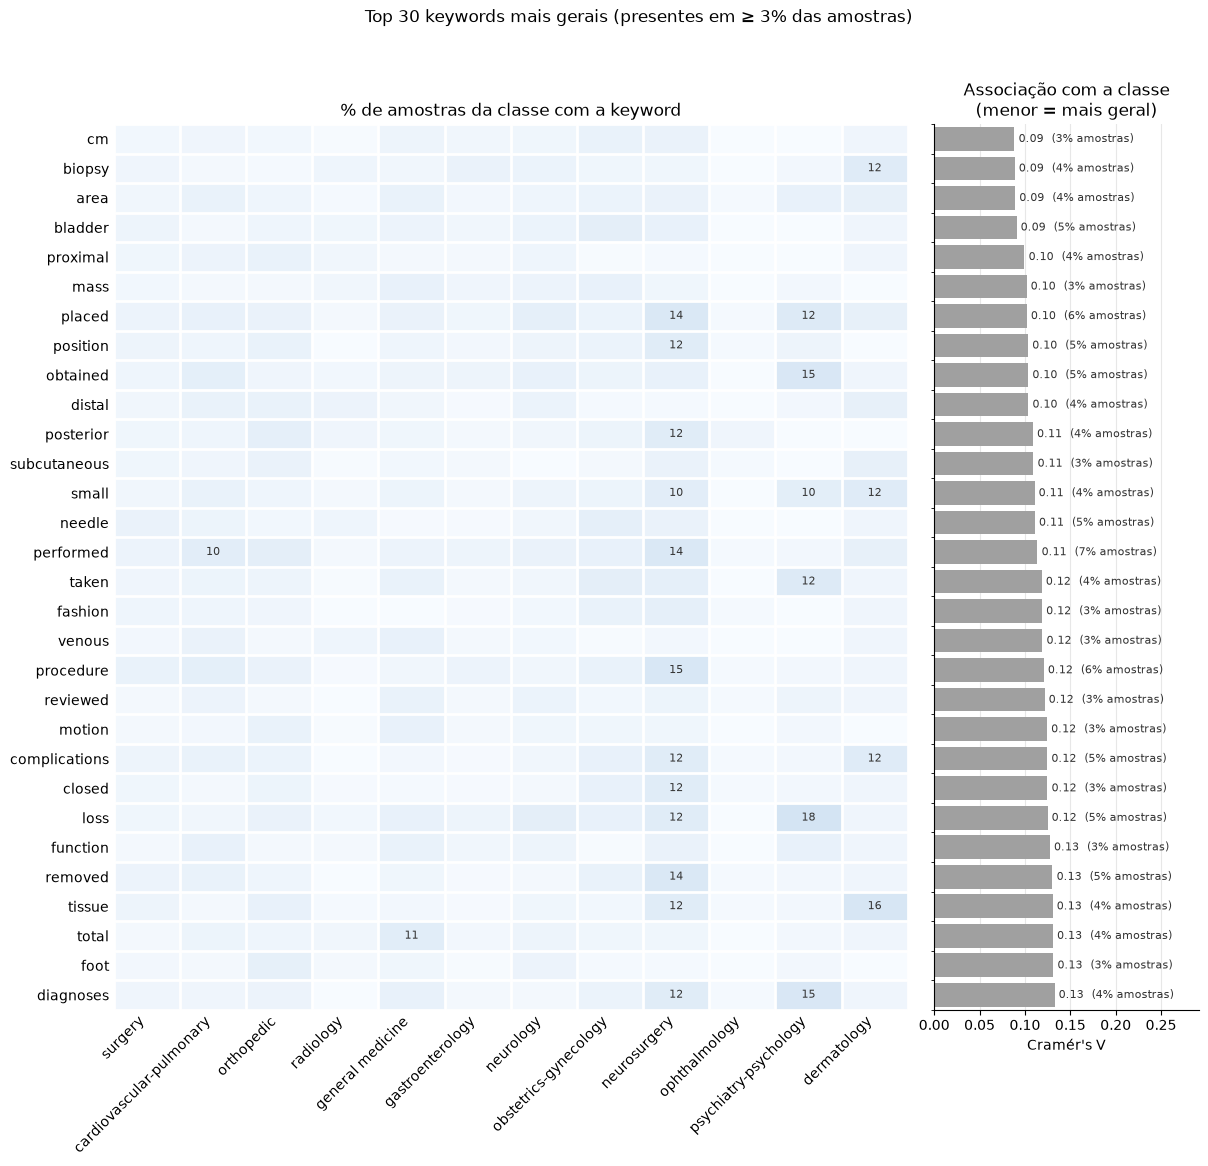

Top 30 keywords mais gerais: cm, biopsy, area, bladder, proximal, mass, placed, position, obtained, distal, posterior, subcutaneous, small, needle, performed, taken, fashion, venous, procedure, reviewed, motion, complications, closed, loss, function, removed, tissue, total, foot, diagnoses


In [92]:
from scipy.stats import chi2_contingency


def plot_most_general_keywords(df: pd.DataFrame, top_n: int = 30, min_freq: float = 0.03):
    kw = df.assign(keyword=df['keywords'].str.split(',')).explode('keyword')
    kw = kw[kw['keyword'] != ''].reset_index()[['index', 'medical_specialty', 'keyword']].drop_duplicates()

    class_size = df['medical_specialty'].value_counts()

    # nº de amostras de cada classe que contêm a keyword
    in_cls = pd.crosstab(kw['keyword'], kw['medical_specialty'])[class_size.index]
    freq   = in_cls.sum(axis=1) / len(df)

    # só keywords frequentes -> keywords raras teriam V baixo só por serem raras
    in_cls = in_cls[freq >= min_freq]

    # Cramér's V: associação keyword <-> classe (0 = nenhuma, 1 = perfeita)
    cramers_v = in_cls.apply(lambda r: np.sqrt(chi2_contingency(np.vstack([r.values, class_size.values - r.values]))[0] / len(df)), axis=1)
    cramers_v = cramers_v.sort_values().head(top_n)

    data = in_cls.loc[cramers_v.index].div(class_size, axis=1) * 100

    fig, (ax, ax_v) = plt.subplots(1, 2, figsize=(14, top_n * 0.3 + 2.5), sharey=True, gridspec_kw={'width_ratios': [3, 1], 'wspace': 0.05})

    im = ax.imshow(data, cmap='Blues', vmin=0, vmax=100, aspect='auto')
    ax.set_xticks(range(len(data.columns)), data.columns, rotation=45, ha='right')
    ax.set_yticks(range(len(data.index)), data.index)
    ax.set_xticks(np.arange(-.5, len(data.columns)), minor=True)
    ax.set_yticks(np.arange(-.5, len(data.index)), minor=True)
    ax.grid(which='minor', color='white', linewidth=2)
    ax.tick_params(which='both', length=0)
    ax.spines[:].set_visible(False)

    for i in range(len(data.index)):
        for j in range(len(data.columns)):
            v = data.iat[i, j]
            if v >= 10:
                ax.text(j, i, f'{v:.0f}', ha='center', va='center', fontsize=8, color='white' if v > 60 else '#333333')

    ax.set_title("% de amostras da classe com a keyword")

    bars = ax_v.barh(range(len(cramers_v)), cramers_v.values, height=0.8, color='#a0a0a0')
    ax_v.bar_label(bars, labels=[f'{v:.2f}  ({freq[k]:.0%} amostras)' for k, v in cramers_v.items()], padding=3, fontsize=8, color='#333333')
    ax_v.set_xlim(0, cramers_v.max() * 2.2)
    ax_v.set_xlabel("Cramér's V")
    ax_v.set_title("Associação com a classe\n(menor = mais geral)")
    ax_v.grid(axis='x', alpha=0.3)
    ax_v.set_axisbelow(True)
    ax_v.tick_params(axis='y', length=0)
    ax_v.spines[['top', 'right']].set_visible(False)

    fig.suptitle(f"Top {top_n} keywords mais gerais (presentes em ≥ {min_freq:.0%} das amostras)")
    plt.show()

    print(f"Top {top_n} keywords mais gerais: {', '.join(cramers_v.index)}")

plot_most_general_keywords(train_df)
